# Classic SVM — Ising phase classification

Baseline RBF-SVM sobre ground states del **Transverse-Field Ising** (`qspin`).

Etiqueta de fase: `y=(h>|J|)`. Features: amplitudes del estado (sin filtrar `h`).


## Librerias


In [1]:
# 1. Import all libraries
import json
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pennylane as qml
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, label_binarize
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

np.random.seed(123)


## Data

PennyLane `qspin` Ising, layouts `open/closed` × `chain/1x4` (4 qubits).


In [2]:
# Load PennyLane qspin Ising (4 qubits) and build phase labels
# Features = ground-state amplitudes (Re||Im). Labels from physics: y=(h > |J|).
# IMPORTANT: h is NOT included as a feature (would leak the label).

ISING_LAYOUTS = [
    {"periodicity": "open", "lattice": "chain", "layout": "1x4"},
    {"periodicity": "closed", "lattice": "chain", "layout": "1x4"},
]


def fix_global_phase(states: np.ndarray) -> np.ndarray:
    """Remove global phase so the first amplitude is real and non-negative when possible."""
    ref = states[:, 0].copy()
    tiny = np.abs(ref) < 1e-12
    if np.any(tiny):
        idx = np.argmax(np.abs(states[tiny]), axis=1)
        ref[tiny] = states[tiny, idx]
        ref[np.abs(ref) < 1e-12] = 1.0
    return states * np.exp(-1j * np.angle(ref))[:, None]


def load_ising_phase_dataset(layouts=ISING_LAYOUTS):
    Xs, ys, meta_h = [], [], []
    for cfg in layouts:
        ds = qml.data.load(
            "qspin",
            sysname="Ising",
            periodicity=cfg["periodicity"],
            lattice=cfg["lattice"],
            layout=cfg["layout"],
        )[0]
        gs = np.asarray(ds.ground_states, dtype=np.complex128)
        gs = fix_global_phase(gs)
        X = np.concatenate([gs.real, gs.imag], axis=1)  # (n, 32) for 4 qubits
        h = np.asarray(ds.parameters["h"], dtype=float)
        J = abs(float(ds.parameters["J"]))
        y = (h > J).astype(int)  # 0 ordered (low h), 1 disordered (high h)
        Xs.append(X)
        ys.append(y)
        meta_h.append(h)
        print(
            f"Loaded Ising {cfg['periodicity']} {cfg['lattice']} {cfg['layout']}: "
            f"X={X.shape}, classes={np.unique(y, return_counts=True)}, hc=|J|={J}"
        )
    X = np.vstack(Xs)
    y = np.concatenate(ys)
    h_all = np.concatenate(meta_h)
    return X, y, h_all


print("Loading Ising phase-classification dataset from PennyLane qspin...")
X_all, y_all, h_all = load_ising_phase_dataset()
print(f"Combined: n={len(X_all)}, features={X_all.shape[1]}, classes={np.unique(y_all, return_counts=True)}")


Loading Ising phase-classification dataset from PennyLane qspin...
Loaded Ising open chain 1x4: X=(100, 32), classes=(array([0, 1]), array([34, 66])), hc=|J|=1.0
Loaded Ising closed chain 1x4: X=(100, 32), classes=(array([0, 1]), array([25, 75])), hc=|J|=1.0
Combined: n=200, features=32, classes=(array([0, 1]), array([ 59, 141]))


## Data Preparation


In [3]:
# Same protocol as Iris/BS: stratified split + PCA->4 + MinMaxScaler[0, pi]
n_qubits = 4
X = X_all
y = y_all

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=123, stratify=y
)
print(f"Custom Dataset Loaded: Train={len(X_train_raw)}, Test={len(X_test_raw)}")

pca = PCA(n_components=n_qubits, random_state=123)
X_train_pca = pca.fit_transform(X_train_raw)
X_test_pca = pca.transform(X_test_raw)
print(f"PCA explained variance ratio sum: {pca.explained_variance_ratio_.sum():.4f}")

minmax = MinMaxScaler(feature_range=(0, np.pi))
X_train = minmax.fit_transform(X_train_pca)
X_test = minmax.transform(X_test_pca)
X_test = np.clip(X_test, 0, np.pi)
n_features = X_train.shape[1]
print(f"Final shapes -> Train: {X_train.shape}, Test: {X_test.shape}")


Custom Dataset Loaded: Train=120, Test=80
PCA explained variance ratio sum: 0.9993
Final shapes -> Train: (120, 4), Test: (80, 4)


## Classic SVM


In [4]:
class ClassicSVM:
    def __init__(self):
        self.model = SVC(kernel="rbf", random_state=42)

    def fit(self, X, y):
        self.model.fit(X, y)
        return self

    def predict(self, X):
        return self.model.predict(X)

    def decision_function(self, X):
        return self.model.decision_function(X)


## Entrenamiento Classic SVM


In [5]:
print("=== Train Classic SVM ===")
svm_model = ClassicSVM()
start = time.time()
svm_model.fit(X_train, y_train)
svm_time = time.time() - start
print(f"Classic SVM training time: {svm_time:.2f}s")


=== Train Classic SVM ===
Classic SVM training time: 0.00s


## Model Evaluation


In [6]:
def evaluate(model, X_t, y_t, classes):
    preds = model.predict(X_t)
    scores = model.decision_function(X_t)
    acc = accuracy_score(y_t, preds)
    prec = precision_score(y_t, preds, average="macro", zero_division=0)
    rec = recall_score(y_t, preds, average="macro", zero_division=0)
    f1 = f1_score(y_t, preds, average="macro", zero_division=0)
    if np.ndim(scores) == 1:
        auc = roc_auc_score(y_t, scores)
    else:
        auc = roc_auc_score(
            label_binarize(y_t, classes=classes), scores, average="macro", multi_class="ovr"
        )
    return acc, prec, rec, f1, auc, scores, preds


In [7]:
classes = np.unique(y_train)
svm_acc, svm_prec, svm_rec, svm_f1, svm_auc, svm_probs, svm_preds = evaluate(svm_model, X_test, y_test, classes)
svm_acc_tr, svm_prec_tr, svm_rec_tr, svm_f1_tr, svm_auc_tr, _, _ = evaluate(svm_model, X_train, y_train, classes)
print("\n=== Train vs Test ===")
print(f"SVM Train - Acc: {svm_acc_tr:.4f} | Prec: {svm_prec_tr:.4f} | Rec: {svm_rec_tr:.4f} | F1: {svm_f1_tr:.4f} | AUC: {svm_auc_tr:.4f}")
print(f"SVM Test  - Acc: {svm_acc:.4f} | Prec: {svm_prec:.4f} | Rec: {svm_rec:.4f} | F1: {svm_f1:.4f} | AUC: {svm_auc:.4f}")



=== Train vs Test ===
SVM Train - Acc: 1.0000 | Prec: 1.0000 | Rec: 1.0000 | F1: 1.0000 | AUC: 1.0000
SVM Test  - Acc: 0.9875 | Prec: 0.9912 | Rec: 0.9792 | F1: 0.9849 | AUC: 1.0000


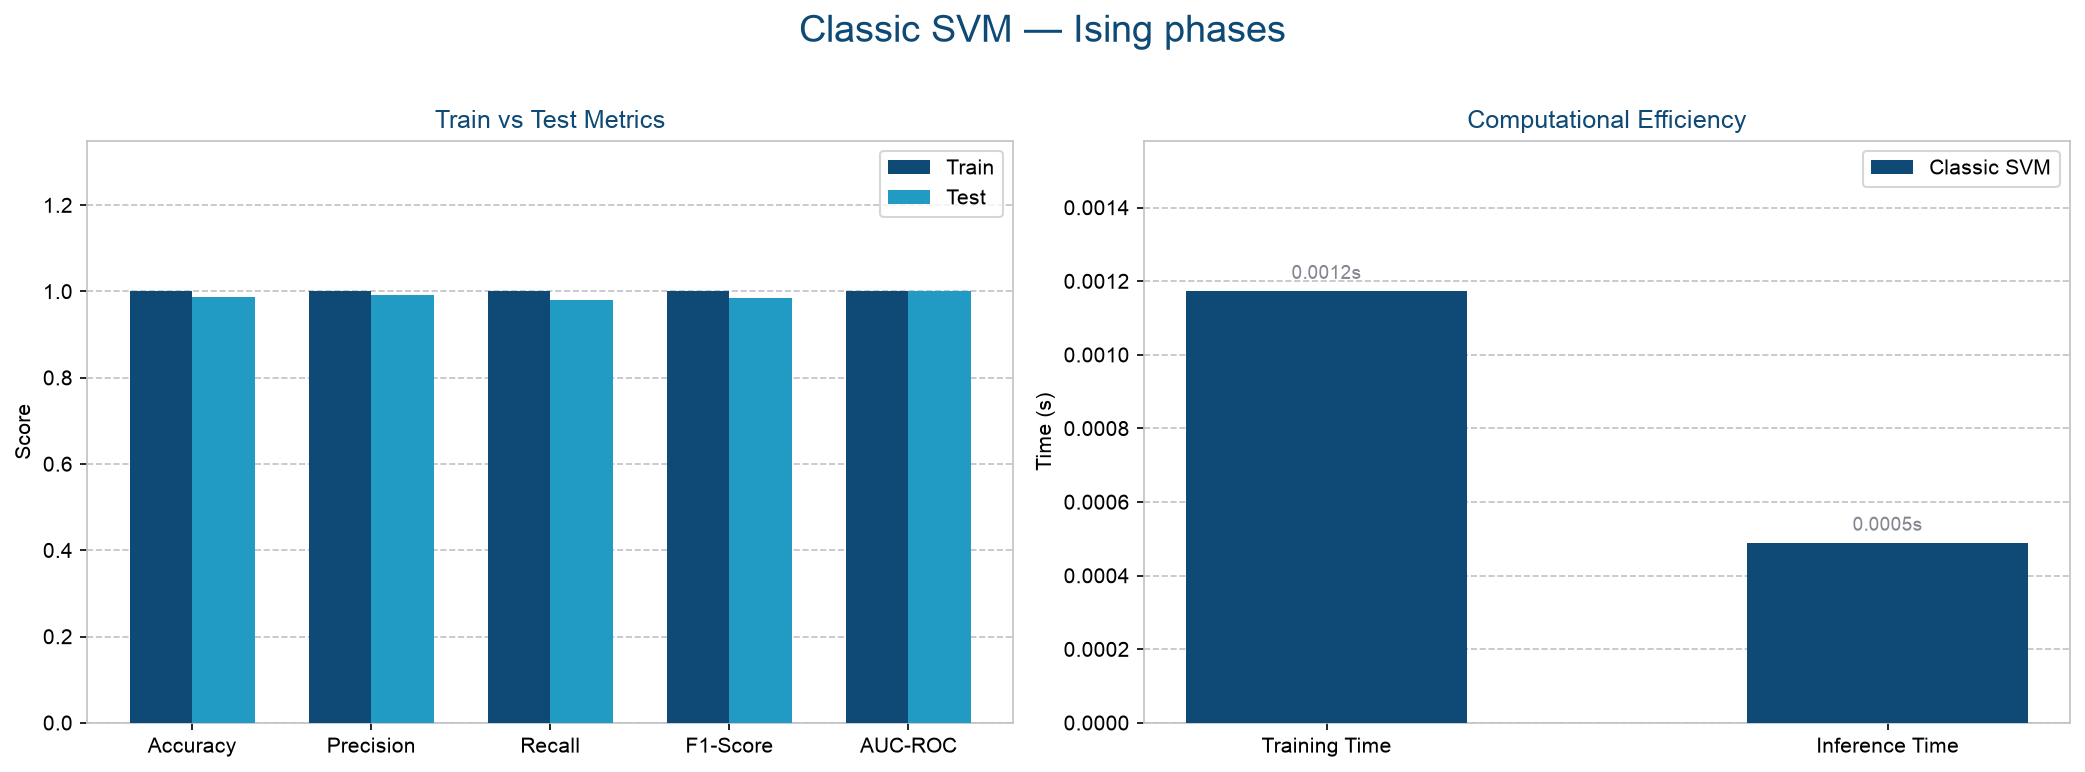

In [8]:
# Result Visualization (train vs test + paleta UNIR)
plt.rcParams.update({
    "font.sans-serif": ["Arial"],
    "axes.edgecolor": "#C0C0C8",
    "grid.color": "#C0C0C8",
    "grid.linestyle": "--",
})

def get_inference_time(model, data):
    start = time.time()
    _ = model.predict(data)
    return time.time() - start

svm_inf_time = get_inference_time(svm_model, X_test)

train_color = "#0E4A75"
test_color = "#219BC3"
unir_gris = "#858591"

fig, axs = plt.subplots(1, 2, figsize=(14, 5), dpi=150)
fig.suptitle("Classic SVM — Ising phases", fontsize=18, y=1.02, color="#0E4A75")

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
train_vals = [svm_acc_tr, svm_prec_tr, svm_rec_tr, svm_f1_tr, svm_auc_tr]
test_vals = [svm_acc, svm_prec, svm_rec, svm_f1, svm_auc]
x = np.arange(len(metrics))
width = 0.35

for i in range(len(metrics)):
    axs[0].bar(x[i] - width / 2, train_vals[i], width, color=train_color,
               label="Train" if i == 0 else "", zorder=3)
    axs[0].bar(x[i] + width / 2, test_vals[i], width, color=test_color,
               label="Test" if i == 0 else "", zorder=3)

axs[0].set_ylabel("Score")
axs[0].set_title("Train vs Test Metrics", color="#0E4A75")
axs[0].set_xticks(x)
axs[0].set_xticklabels(metrics)
axs[0].set_ylim(0, 1.35)
axs[0].legend(loc="upper right")
axs[0].grid(axis="y", zorder=0)

eff_labels = ["Training Time", "Inference Time"]
eff = [svm_time, svm_inf_time]
x_eff = np.arange(len(eff_labels))
axs[1].bar(x_eff, eff, 0.5, color="#0E4A75", label="Classic SVM", zorder=3)
axs[1].set_xticks(x_eff)
axs[1].set_xticklabels(eff_labels)
axs[1].set_ylabel("Time (s)")
axs[1].set_title("Computational Efficiency", color="#0E4A75")
max_time = max(eff)
axs[1].set_ylim(0, max_time * 1.35 if max_time > 0 else 1)
axs[1].legend(loc="upper right")
axs[1].grid(axis="y", zorder=0)
offset = max_time * 0.02 if max_time > 0 else 0.02
for i in range(2):
    axs[1].text(x_eff[i], eff[i] + offset, f"{eff[i]:.4f}s",
                ha="center", va="bottom", fontsize=9, color=unir_gris)

plt.tight_layout()
plt.show()


## Guardar resultados


In [9]:
# Save metrics for IsingClassification comparison
# METRICS_PATH_OK: case_paths (no uses quantum/classical vars)
import json
from pathlib import Path
import sys

for _base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    _lib = _base / "Notebooks" / "lib"
    if (_lib / "case_paths.py").is_file():
        _s = str(_lib)
        if _s not in sys.path:
            sys.path.insert(0, _s)
        break
else:
    raise FileNotFoundError("Notebooks/lib/case_paths.py not found")

import importlib
import case_paths as _case_paths
importlib.reload(_case_paths)
from case_paths import resolve_metrics_dir as _resolve_metrics_dir

def resolve_metrics_dir() -> Path:
    """Guarda en Notebooks/Classification/IsingClassification/metrics (helper compartido)."""
    return _resolve_metrics_dir("Classification", "IsingClassification")

metrics_dir = resolve_metrics_dir()



payload = {
    "model": "SVM",
    "family": "classical",
    "protocol": {
        "dataset": "qspin-ising",
        "layouts": ["open/chain/1x4", "closed/chain/1x4"],
        "features": "ground_state Re||Im (32) -> PCA(4)",
        "label_rule": "y=(h > |J|) with J=-1 (1D TFIM critical field)",
        "n_features": int(n_features),
        "n_qubits": 4,
        "test_size": 0.4,
        "random_state": 123,
        "stratify": True,
        "scaler": "MinMaxScaler[0, pi]",
        "pca": "PCA(n_components=4)",
    },
    "train": {
        "accuracy": float(svm_acc_tr),
        "precision": float(svm_prec_tr),
        "recall": float(svm_rec_tr),
        "f1": float(svm_f1_tr),
        "auc": float(svm_auc_tr),
    },
    "test": {
        "accuracy": float(svm_acc),
        "precision": float(svm_prec),
        "recall": float(svm_rec),
        "f1": float(svm_f1),
        "auc": float(svm_auc),
    },
    "train_time_s": float(svm_time),
    "inference_time_s": float(svm_inf_time),
}

out = metrics_dir / "svm_ising.json"
out.write_text(json.dumps(payload, indent=2))
print("Saved:", out)


Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Classification/IsingClassification/metrics/svm_ising.json


## Storytelling plots

`figures/`: PCA sin frontera + con frontera del **mismo** modelo ya entrenado.
Puntos test usan `*_preds` del notebook; la malla usa `modelo.predict` (sin reentrenar).


/Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/lib/storytelling.py:74: UserWarning: Glyph 10216 (\N{MATHEMATICAL LEFT ANGLE BRACKET}) missing from font(s) Arial.
  fig.savefig(path, bbox_inches="tight", facecolor="white", dpi=150)
/Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/lib/storytelling.py:74: UserWarning: Glyph 10217 (\N{MATHEMATICAL RIGHT ANGLE BRACKET}) missing from font(s) Arial.
  fig.savefig(path, bbox_inches="tight", facecolor="white", dpi=150)
/Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10216 (\N{MATHEMATICAL LEFT ANGLE BRACKET}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10217 (\N{MATHEMATICAL RIGHT ANGLE BRACKE

Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Classification/IsingClassification/figures/svm_ising_spin_heatmap.png


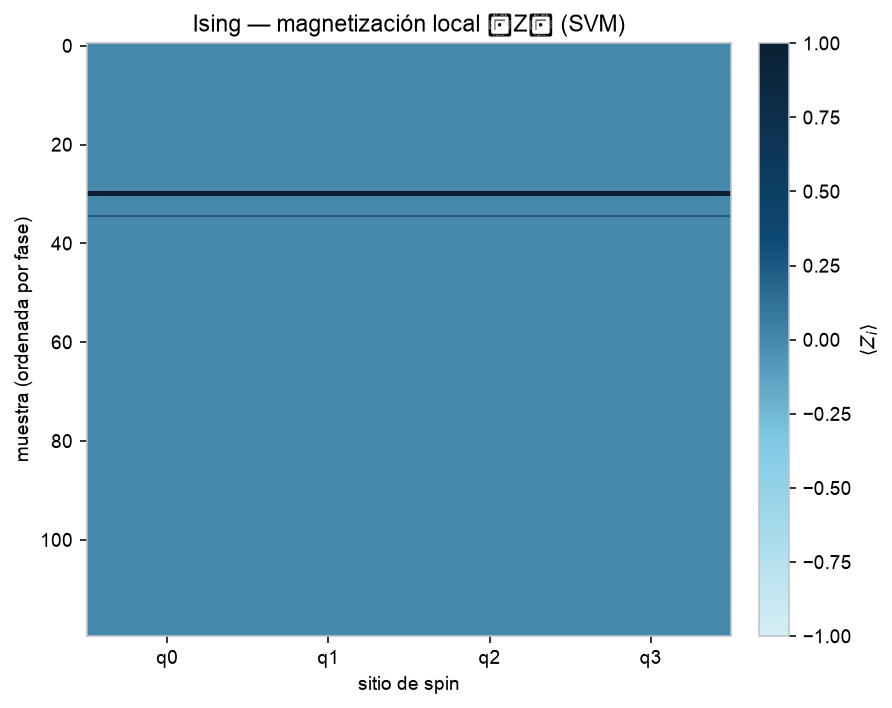

Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Classification/IsingClassification/figures/svm_ising_chain.png


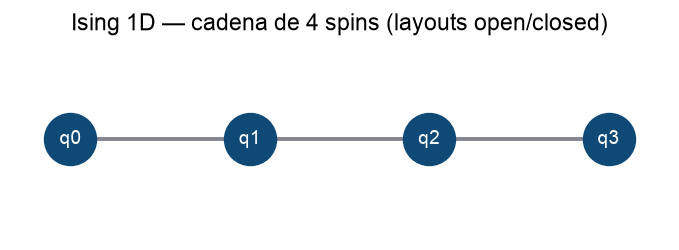

Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Classification/IsingClassification/figures/svm_ising_pca_scatter.png


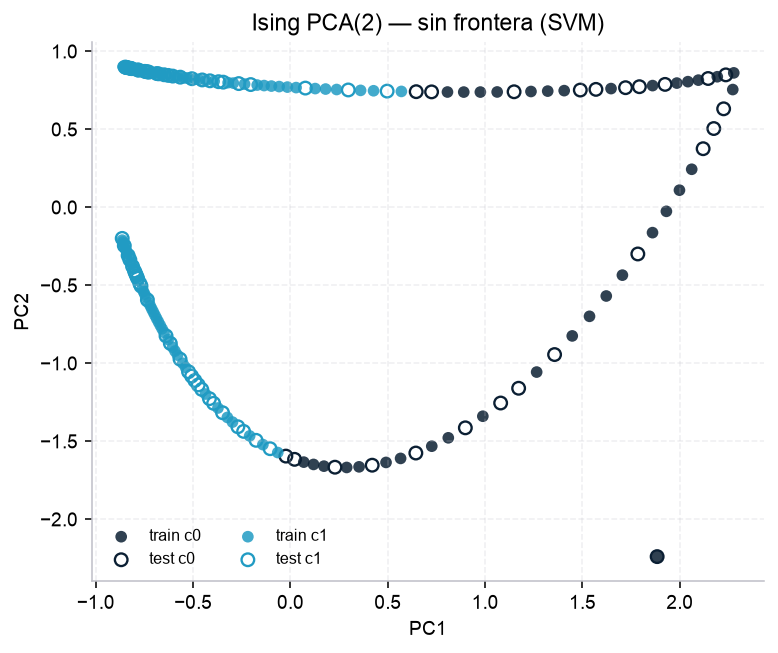

Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Classification/IsingClassification/figures/svm_ising_pca_boundary.png


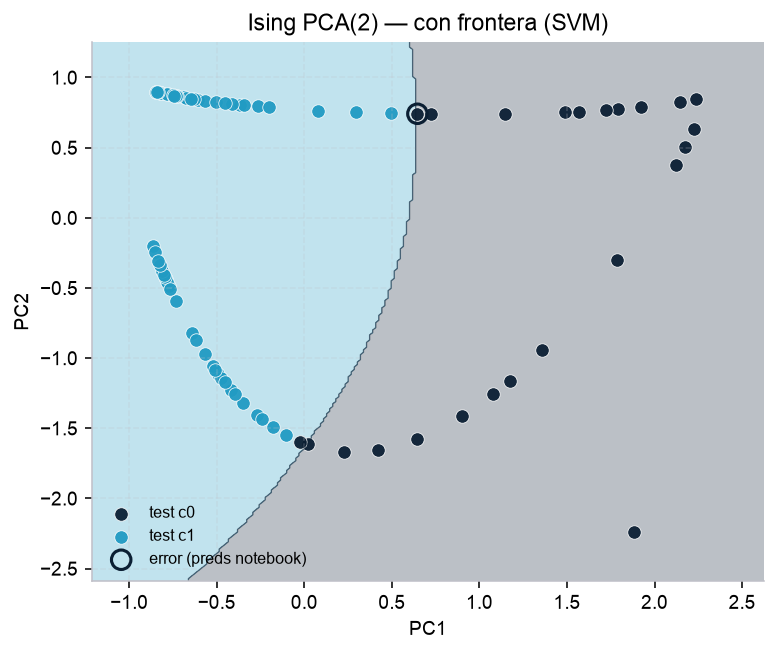

In [10]:
# --- storytelling plots (auto) ---
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

for _base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    _lib = _base / "Notebooks" / "lib"
    if (_lib / "storytelling.py").is_file():
        _s = str(_lib)
        if _s not in sys.path:
            sys.path.insert(0, _s)
        break
else:
    raise FileNotFoundError("Notebooks/lib/storytelling.py not found")

import importlib
import storytelling as _storytelling
importlib.reload(_storytelling)
from storytelling import resolve_figures_dir, plot_ising_story

figures_dir = resolve_figures_dir("Classification", "IsingClassification")
predict_fn = svm_model.predict
_raw = X_train_raw if "X_train_raw" in globals() else X_train
plot_ising_story(
    _raw, y_train,
    figures_dir=figures_dir,
    stem="svm",
    title_model="SVM",
    X_train=X_train,
    X_test=X_test,
    y_test=y_test,
    y_pred_test=svm_preds,
    predict_fn=predict_fn,
)

plt.show()
